## Настройки

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from catboost import CatBoostClassifier
from sklearn.metrics import roc_auc_score, average_precision_score
from sksurv.nonparametric import kaplan_meier_estimator
from IPython.display import display

ROOT = Path(r"C:\Users\Ева\Desktop\Хакатон Альфа\AURELIUS\scoring")
DATA_PATH = ROOT / "data/processed/ml_survival_dataset.parquet"
SPLIT_PATH = ROOT / "models/experiments/survival_v3_baseline/splits.npz"
FEATURES_PATH = ROOT / "models/experiments/survival_v3_discrete_time/features.json"
MODEL_PATHS = {
    "baseline": ROOT / "models/experiments/survival_v3_discrete_time/model.cbm",
    "optuna_stage1": ROOT / "models/experiments/survival_v3_optuna/best_model.cbm",
    "optuna_stage2": ROOT / "models/experiments/survival_v3_optuna_stage2/best_model.cbm",
}
OUT = ROOT / "models/experiments/survival_v3_final_evaluation"
OUT.mkdir(parents=True, exist_ok=True)
SEED = 42
N_BOOTSTRAP = 300
BATCH_SIZE = 1500
HORIZONS_BY_TERM = {
    12: [6], 18: [6, 12], 24: [6, 12, 18],
    36: [6, 12, 24], 48: [6, 12, 24, 36],
    60: [6, 12, 24, 36, 48],
}
for path in [DATA_PATH, SPLIT_PATH, FEATURES_PATH, *MODEL_PATHS.values()]:
    if not path.exists():
        raise FileNotFoundError(f"Отсутствует файл: {path}")
print("Выходная папка:", OUT)


Выходная папка: C:\Users\Ева\Desktop\Хакатон Альфа\AURELIUS\scoring\models\experiments\survival_v3_final_evaluation


## Данные и разделение

In [2]:
df = pd.read_parquet(DATA_PATH)
with np.load(SPLIT_PATH) as s:
    train_idx, val_idx, test_idx = (s[k].copy() for k in ["train_idx", "val_idx", "test_idx"])
with open(FEATURES_PATH, encoding="utf-8") as f:
    feature_cfg = json.load(f)
MODEL_FEATURES = feature_cfg["features"]
CAT_FEATURES = feature_cfg["categorical_features"]
BASE_FEATURES = [f for f in MODEL_FEATURES if f != "month_on_book"]
assert "month_on_book" in MODEL_FEATURES and "term_months" not in MODEL_FEATURES
assert len(np.unique(np.concatenate([train_idx, val_idx, test_idx]))) == len(df)
train = df.iloc[train_idx].reset_index(drop=True)
val = df.iloc[val_idx].reset_index(drop=True)
test = df.iloc[test_idx].reset_index(drop=True)
for a, b in [(train, val), (train, test), (val, test)]:
    assert set(a.borrower_id).isdisjoint(set(b.borrower_id)), "Пересечение borrower_id между выборками"
assert ((df.duration >= 1) & (df.duration <= df.term_months)).all()
assert df.event.isin([0, 1]).all()
models = {}
for name, path in MODEL_PATHS.items():
    model = CatBoostClassifier()
    model.load_model(str(path))
    models[name] = model
print("Train / validation / test:", len(train), len(val), len(test))
print("Модели:", ", ".join(models))


Train / validation / test: 140000 30000 30000
Модели: baseline, optuna_stage1, optuna_stage2


## Прогнозы накопленной PD

In [3]:
def predict_pd(model, episodes, batch_size=BATCH_SIZE):
    """Прогноз от даты выдачи до договорного срока; test-метки не используются."""
    result = np.empty(len(episodes), dtype=object)
    for left in range(0, len(episodes), batch_size):
        chunk = episodes.iloc[left:left + batch_size].reset_index(drop=True)
        terms = chunk.term_months.to_numpy(dtype=np.int32)
        ids = np.repeat(np.arange(len(chunk)), terms)
        ends = np.cumsum(terms, dtype=np.int64)
        starts = ends - terms
        months = (np.arange(len(ids)) - np.repeat(starts, terms) + 1).astype(np.int16)
        X = chunk.iloc[ids][BASE_FEATURES].reset_index(drop=True).copy()
        X["month_on_book"] = months
        X = X[MODEL_FEATURES]
        for col in CAT_FEATURES:
            X[col] = X[col].fillna("UNKNOWN").astype(str)
        hazard = np.clip(model.predict_proba(X)[:, 1], 1e-10, 1 - 1e-10)
        for j, (start, end) in enumerate(zip(starts, ends)):
            result[left + j] = -np.expm1(np.cumsum(np.log1p(-hazard[start:end])))
    return result

# Валидация используется только для диагностики калибровки.
# Test — один раз для финального сравнения уже зафиксированных моделей.
predictions = {"validation": {}, "test": {}}
for sample_name, episodes in [("validation", val), ("test", test)]:
    for model_name, model in models.items():
        print(f"Прогноз: {sample_name} / {model_name}", flush=True)
        predictions[sample_name][model_name] = predict_pd(model, episodes)
print("Прогнозы готовы")


Прогноз: validation / baseline
Прогноз: validation / optuna_stage1
Прогноз: validation / optuna_stage2
Прогноз: test / baseline
Прогноз: test / optuna_stage1
Прогноз: test / optuna_stage2
Прогнозы готовы


## IPCW и метрики

In [4]:
def km_censoring(train_group):
    # KM для цензурирования: событие censor = 1-event
    times, survival = kaplan_meier_estimator(
        (~train_group.event.astype(bool)).to_numpy(),
        train_group.duration.to_numpy(dtype=float),
    )
    return np.asarray(times, float), np.asarray(survival, float)

def g_at(times, survival, t, left=False):
    idx = np.searchsorted(times, t, side="left" if left else "right") - 1
    idx = np.asarray(idx)
    return np.where(idx >= 0, survival[np.maximum(idx, 0)], 1.0)

def ipcw_arrays(episodes, horizon, censor_km):
    t = episodes.duration.to_numpy(dtype=float)
    event = episodes.event.to_numpy(dtype=bool)
    positive = event & (t <= horizon)
    negative = t > horizon
    times, surv = censor_km
    g_event = g_at(times, surv, t, left=True)  # G(T-)
    g_horizon = float(g_at(times, surv, float(horizon)))
    if g_horizon <= 1e-8 or np.any(g_event[positive] <= 1e-8):
        raise ValueError(f"Нет поддержки IPCW на горизонте {horizon}")
    weights = np.zeros(len(episodes), dtype=float)
    weights[positive] = 1.0 / g_event[positive]
    weights[negative] = 1.0 / g_horizon
    return positive.astype(int), weights

def weighted_metrics(y, w, p, reference_p=None):
    valid = w > 0
    yy, ww, pp = y[valid], w[valid], np.asarray(p)[valid]
    brier = float(np.sum(ww * (yy - pp)**2) / len(y))
    result = {"ipcw_brier": brier, "roc_auc": np.nan, "gini": np.nan, "pr_auc": np.nan}
    if len(np.unique(yy)) == 2:
        auc = float(roc_auc_score(yy, pp, sample_weight=ww))
        result["roc_auc"] = auc
        result["gini"] = 2 * auc - 1
        result["pr_auc"] = float(average_precision_score(yy, pp, sample_weight=ww))
    if reference_p is not None:
        ref_brier = float(np.sum(ww * (yy - reference_p)**2) / len(y))
        result["km_brier"] = ref_brier
        result["brier_skill_score"] = 1 - brier / ref_brier if ref_brier > 0 else np.nan
    return result

def km_default_pd(train_group, horizon):
    t, s = kaplan_meier_estimator(
        train_group.event.to_numpy(dtype=bool),
        train_group.duration.to_numpy(dtype=float),
    )
    return float(1 - g_at(np.asarray(t), np.asarray(s), horizon))

def horizon_predictions(curves, positions, horizon):
    return np.fromiter((curves[i][horizon - 1] for i in positions),
                       dtype=float, count=len(positions))

# Зафиксированные на train оценки цензурирования и наивной PD
reference = {}
for term, horizons in HORIZONS_BY_TERM.items():
    group = train.loc[train.term_months == term]
    assert len(group) > 0, f"Нет train для срока {term}"
    km = km_censoring(group)
    for horizon in horizons:
        reference[(term, horizon)] = {
            "censor_km": km,
            "naive_pd": km_default_pd(group, horizon),
        }
print("Референсные оценки построены только на train")


Референсные оценки построены только на train


## Оценка на validation и test

In [5]:
metric_rows = []
arrays = {}
for sample_name, episodes in [("validation", val), ("test", test)]:
    for term, horizons in HORIZONS_BY_TERM.items():
        pos = np.flatnonzero(episodes.term_months.to_numpy() == term)
        group = episodes.iloc[pos].reset_index(drop=True)
        if len(group) == 0:
            continue
        for horizon in horizons:
            ref = reference[(term, horizon)]
            y, w = ipcw_arrays(group, horizon, ref["censor_km"])
            arrays[(sample_name, term, horizon)] = {
                "y": y, "w": w, "borrower_id": group.borrower_id.to_numpy(),
                "p": {}, "naive_pd": ref["naive_pd"],
            }
            for model_name in models:
                p = horizon_predictions(predictions[sample_name][model_name], pos, horizon)
                arrays[(sample_name, term, horizon)]["p"][model_name] = p
                scores = weighted_metrics(y, w, p, ref["naive_pd"])
                metric_rows.append({
                    "sample": sample_name, "model": model_name,
                    "term_months": term, "horizon_months": horizon,
                    "n_episodes": len(group), "n_events_by_horizon": int(y.sum()),
                    "naive_pd": ref["naive_pd"], **scores,
                })
metrics = pd.DataFrame(metric_rows)
metrics.to_csv(OUT / "metrics_by_horizon.csv", index=False)
display(metrics.query("sample == 'test'").round(5))


,sample,model,term_months,horizon_months,n_episodes,n_events_by_horizon,naive_pd,ipcw_brier,roc_auc,gini,pr_auc,km_brier,brier_skill_score
54,test,baseline,12,6,4868,357,0.07860,0.06361,0.71236,0.42473,0.21167,0.06799,0.06431
55,test,optuna_stage1,12,6,4868,357,0.07860,0.06356,0.71601,0.43202,0.21205,0.06799,0.06503
56,test,optuna_stage2,12,6,4868,357,0.07860,0.06356,0.71548,0.43096,0.21241,0.06799,0.06516
57,test,baseline,18,6,3909,316,0.07647,0.06948,0.69949,0.39898,0.22062,0.07432,0.06523
58,test,optuna_stage1,18,6,3909,316,0.07647,0.06952,0.69980,0.39961,0.21887,0.07432,0.06464
59,test,optuna_stage2,18,6,3909,316,0.07647,0.06930,0.70265,0.40530,0.22398,0.07432,0.06756
60,test,baseline,18,12,3909,568,0.14538,0.11429,0.68532,0.37064,0.33539,0.12539,0.08848
61,test,optuna_stage1,18,12,3909,568,0.14538,0.11407,0.68754,0.37508,0.33631,0.12539,0.09026
62,test,optuna_stage2,18,12,3909,568,0.14538,0.11388,0.69054,0.38108,0.33941,0.12539,0.09178
63,test,baseline,24,6,7260,640,0.08005,0.07404,0.70998,0.41997,0.25153,0.08045,0.07963


## Сводные метрики

In [ ]:
# Взвешиваем каждую комбинацию (срок, горизонт) по числу кредитов
aggregate_rows = []
for (sample, model), part in metrics.groupby(["sample", "model"]):
    row = {"sample": sample, "model": model}
    for metric in ["ipcw_brier", "km_brier", "brier_skill_score", "roc_auc", "gini", "pr_auc"]:
        ok = part[metric].notna()
        row[metric] = float(np.average(part.loc[ok, metric], weights=part.loc[ok, "n_episodes"])) if ok.any() else np.nan
    row["brier_skill_score"] = 1 - row["ipcw_brier"] / row["km_brier"]
    aggregate_rows.append(row)
summary = pd.DataFrame(aggregate_rows).sort_values(["sample", "ipcw_brier"])
summary.to_csv(OUT / "metrics_summary.csv", index=False)
display(summary.round(6))


,sample,model,ipcw_brier,km_brier,brier_skill_score,roc_auc,gini,pr_auc
2,test,optuna_stage2,0.127430,0.142408,0.105178,0.693425,0.386850,0.389447
1,test,optuna_stage1,0.127547,0.142408,0.104355,0.692441,0.384883,0.388112
0,test,baseline,0.128006,0.142408,0.101130,0.689358,0.378717,0.385294
5,validation,optuna_stage2,0.124742,0.139739,0.107321,0.695853,0.391706,0.382485
4,validation,optuna_stage1,0.124971,0.139739,0.105686,0.694546,0.389092,0.380138
3,validation,baseline,0.125289,0.139739,0.103405,0.692000,0.383999,0.379634


## Bootstrap по заёмщикам

In [7]:
# Парный cluster-bootstrap: все эпизоды одного borrower_id выбираются вместе.
# Повторно используем IPCW-веса, оцененные по train; учитываем вариацию test,
rng = np.random.default_rng(SEED)
boot_rows = []
for (sample_name, term, horizon), arr in arrays.items():
    if sample_name != "test":
        continue
    borrower_ids = arr["borrower_id"]
    unique_ids, inv = np.unique(borrower_ids, return_inverse=True)
    groups = [np.flatnonzero(inv == k) for k in range(len(unique_ids))]
    y, w = arr["y"], arr["w"]
    for b in range(N_BOOTSTRAP):
        sampled_groups = rng.integers(0, len(groups), size=len(groups))
        idx = np.concatenate([groups[j] for j in sampled_groups])
        for model_name, p in arr["p"].items():
            result = weighted_metrics(y[idx], w[idx], p[idx], arr["naive_pd"])
            boot_rows.append({
                "bootstrap": b, "term_months": term,
                "horizon_months": horizon, "model": model_name,
                **result,
            })
boot = pd.DataFrame(boot_rows)
boot.to_csv(OUT / "bootstrap_metrics.csv", index=False)
ci_rows = []
for (term, horizon, model), g in boot.groupby(["term_months", "horizon_months", "model"]):
    for metric in ["ipcw_brier", "roc_auc", "gini", "pr_auc", "brier_skill_score"]:
        vals = g[metric].dropna().to_numpy()
        if len(vals) < N_BOOTSTRAP * .9:
            lo, hi = np.nan, np.nan
        else:
            lo, hi = np.quantile(vals, [0.025, 0.975])
        ci_rows.append({
            "term_months": term, "horizon_months": horizon,
            "model": model, "metric": metric, "ci_low": lo, "ci_high": hi,
        })
ci = pd.DataFrame(ci_rows)
ci.to_csv(OUT / "bootstrap_confidence_intervals.csv", index=False)
display(ci.query("model == 'optuna_stage2'").round(5))


,term_months,horizon_months,model,metric,ci_low,ci_high
10,12,6,optuna_stage2,ipcw_brier,0.05904,0.06912
11,12,6,optuna_stage2,roc_auc,0.68799,0.74213
12,12,6,optuna_stage2,gini,0.37599,0.48425
13,12,6,optuna_stage2,pr_auc,0.17695,0.25518
14,12,6,optuna_stage2,brier_skill_score,0.04130,0.08654
...,...,...,...,...,...,...
265,60,48,optuna_stage2,ipcw_brier,0.21378,0.23162
266,60,48,optuna_stage2,roc_auc,0.66103,0.71088
267,60,48,optuna_stage2,gini,0.32205,0.42176
268,60,48,optuna_stage2,pr_auc,0.70377,0.75990


## Различия моделей

In [8]:
# Парные разности метрик при одинаковых bootstrap-выборках.
# Положительный delta_brier означает улучшение stage2 (Brier ниже).
diff_rows = []
for (term, horizon), g in boot.groupby(["term_months", "horizon_months"]):
    piv = g.pivot(index="bootstrap", columns="model", values="ipcw_brier")
    for challenger in ["baseline", "optuna_stage1"]:
        delta = piv[challenger] - piv["optuna_stage2"]
        diff_rows.append({
            "term_months": term, "horizon_months": horizon,
            "comparison": f"stage2_vs_{challenger}",
            "mean_delta_brier": float(delta.mean()),
            "ci_low": float(delta.quantile(0.025)),
            "ci_high": float(delta.quantile(0.975)),
            "ci_excludes_zero": bool(delta.quantile(0.025) > 0 or delta.quantile(0.975) < 0),
        })
diff = pd.DataFrame(diff_rows)
diff.to_csv(OUT / "paired_bootstrap_differences.csv", index=False)
display(diff.round(6))


,term_months,horizon_months,comparison,mean_delta_brier,ci_low,ci_high,ci_excludes_zero
0,12,6,stage2_vs_baseline,0.000074,-0.000169,0.000330,False
1,12,6,stage2_vs_optuna_stage1,0.000014,-0.000223,0.000226,False
2,18,6,stage2_vs_baseline,0.000169,-0.000205,0.000495,False
3,18,6,stage2_vs_optuna_stage1,0.000207,-0.000087,0.000506,False
4,18,12,stage2_vs_baseline,0.000386,-0.000138,0.000911,False
5,18,12,stage2_vs_optuna_stage1,0.000194,-0.000180,0.000642,False
6,24,6,stage2_vs_baseline,0.000130,-0.000151,0.000376,False
7,24,6,stage2_vs_optuna_stage1,0.000115,-0.000080,0.000322,False
8,24,12,stage2_vs_baseline,0.000383,-0.000005,0.000724,False
9,24,12,stage2_vs_optuna_stage1,0.000184,-0.000089,0.000444,False


## Калибровка PD

Калибровка рассчитана.
Количество строк: 360

Калибровка на validation:


,sample,term_months,horizon_months,weighted_abs_calibration_error,weighted_bias_observed_minus_predicted
18,validation,12,6,0.008039,-0.003943
19,validation,18,6,0.009363,-0.005550
20,validation,18,12,0.012664,-0.009677
21,validation,24,6,0.005686,-0.000610
22,validation,24,12,0.012447,-0.006273
23,validation,24,18,0.012190,-0.008623
24,validation,36,6,0.008160,0.003833
25,validation,36,12,0.013600,0.007289
26,validation,36,24,0.017605,0.005678
27,validation,48,6,0.011519,-0.005282



Калибровка на test:


,sample,term_months,horizon_months,weighted_abs_calibration_error,weighted_bias_observed_minus_predicted
0,test,12,6,0.011318,-0.008596
1,test,18,6,0.005539,-0.000338
2,test,18,12,0.010094,-0.008494
3,test,24,6,0.008473,0.005316
4,test,24,12,0.009972,0.006300
5,test,24,18,0.014845,0.003190
6,test,36,6,0.012873,0.005213
7,test,36,12,0.016961,0.005277
8,test,36,24,0.015981,-0.000249
9,test,48,6,0.015730,0.012164



Количество сочетаний: 18


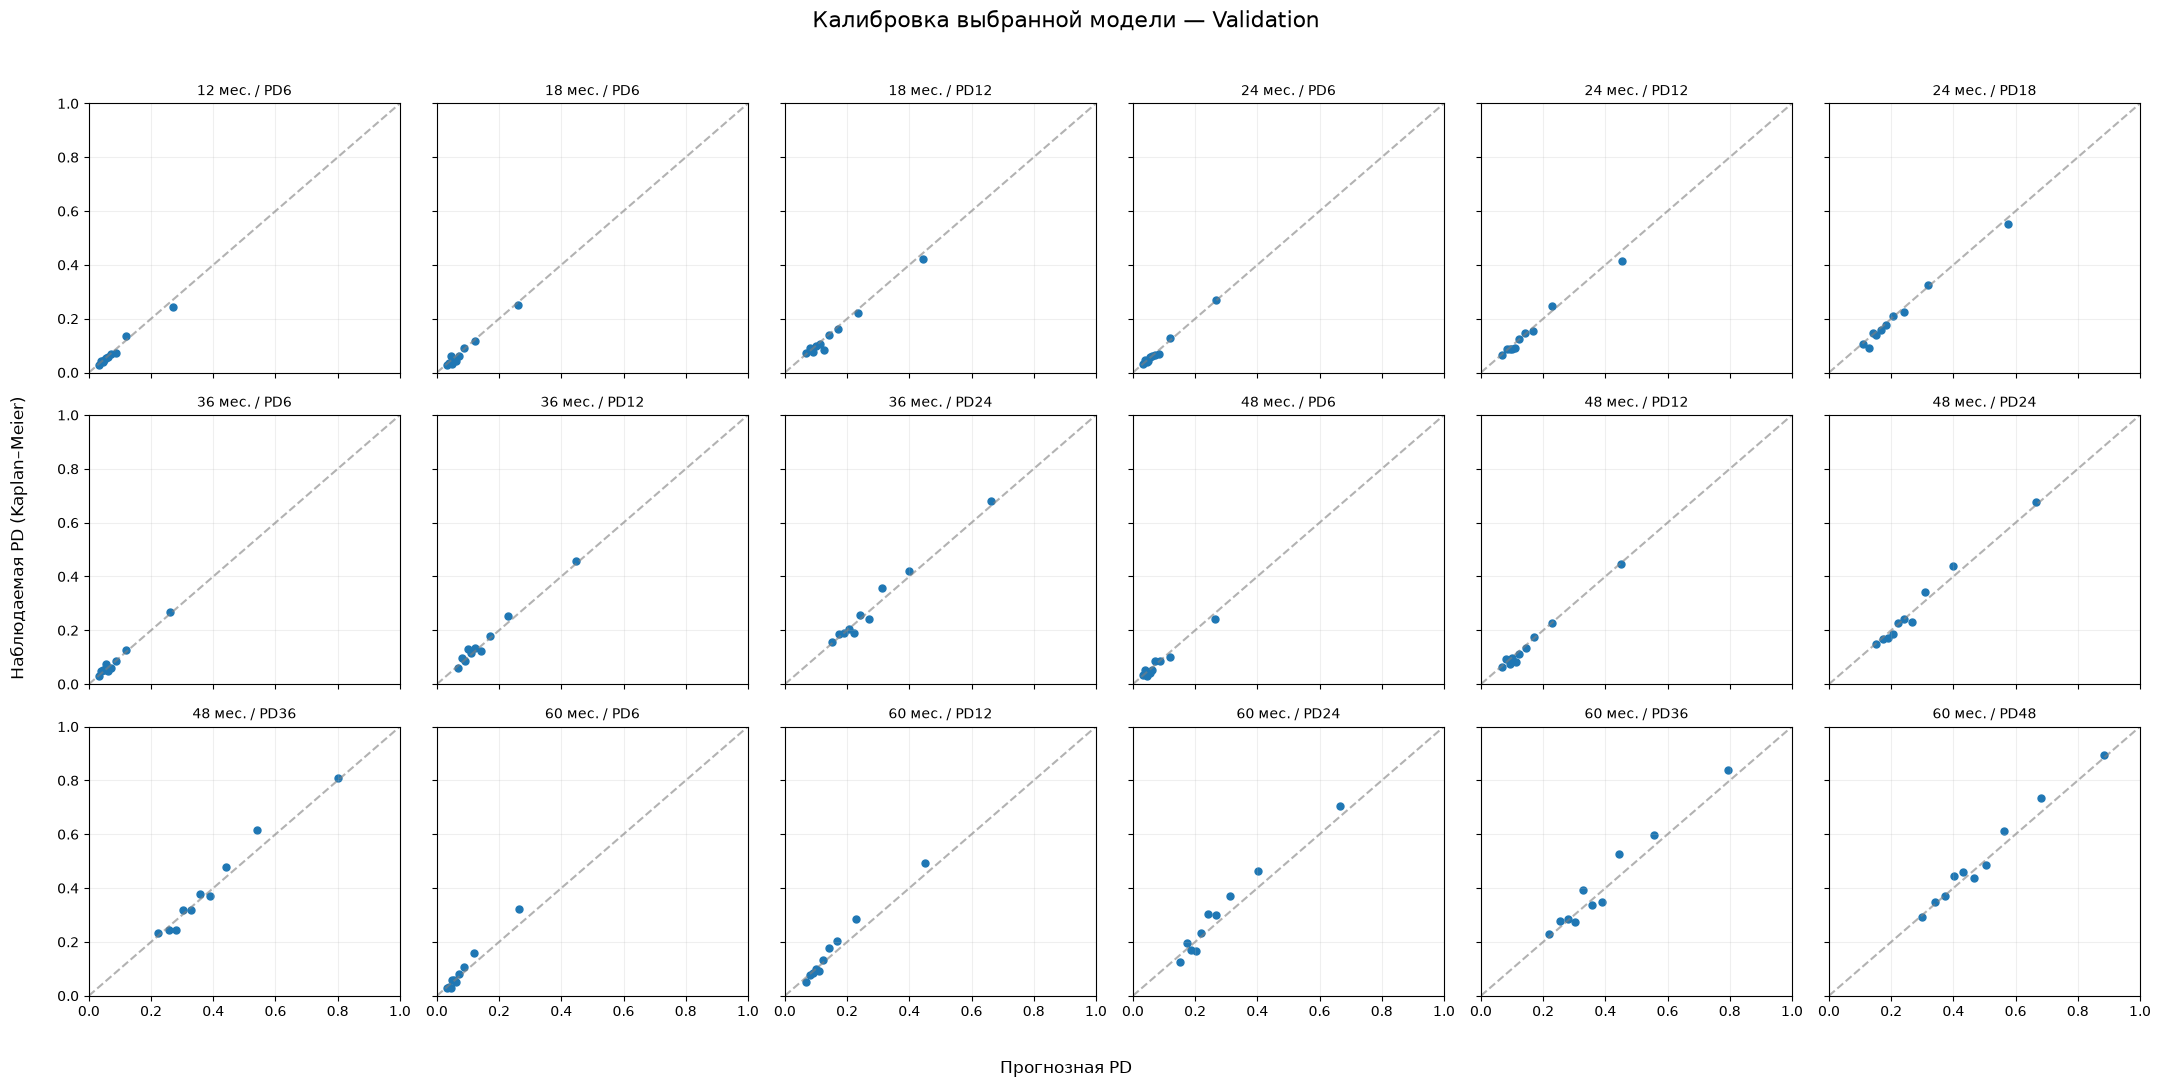

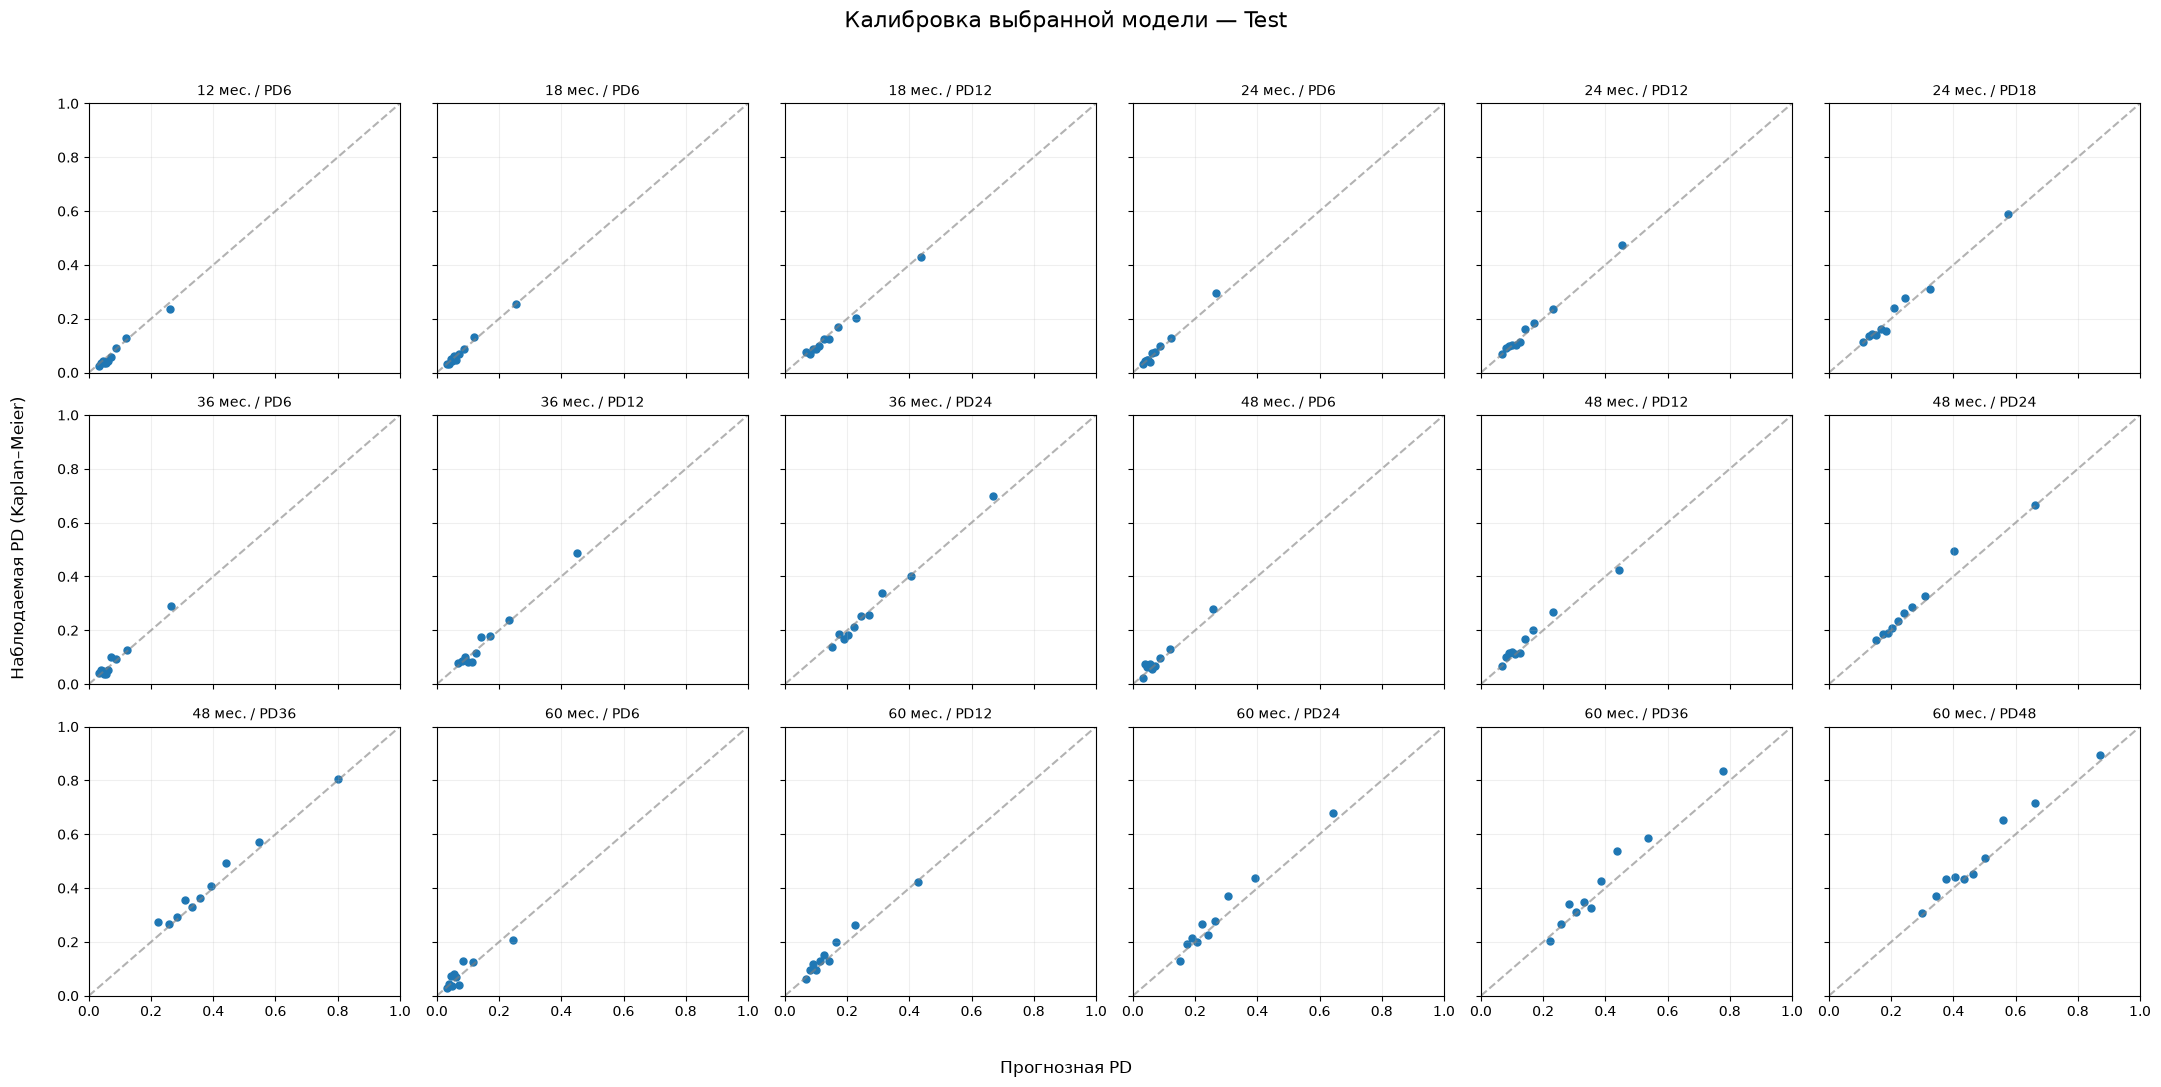


ИТОГИ КАЛИБРОВКИ

VALIDATION
Средняя абсолютная ошибка: 0.01673
Максимальная абсолютная ошибка: 0.036897
Среднее смещение: 0.003165

TEST
Средняя абсолютная ошибка: 0.017639
Максимальная абсолютная ошибка: 0.037464
Среднее смещение: 0.009441

Файлы сохранены в:
C:\Users\Ева\Desktop\Хакатон Альфа\AURELIUS\scoring\models\experiments\survival_v3_final_evaluation


In [9]:
# ============================================================
# КАЛИБРОВКА PD — VALIDATION И TEST
# ============================================================

def observed_pd_km(episodes, horizon):
    t, s = kaplan_meier_estimator(
        episodes["event"].to_numpy(dtype=bool),
        episodes["duration"].to_numpy(dtype=float),
    )

    return float(
        1 - g_at(
            np.asarray(t),
            np.asarray(s),
            horizon,
        )
    )


# ============================================================
# 1. РАСЧЁТ КАЛИБРОВКИ
# ============================================================

calibration_rows = []

for (sample_name, term, horizon), arr in arrays.items():

    episodes = val if sample_name == "validation" else test

    episodes = episodes.loc[
        episodes["term_months"] == term
    ].reset_index(drop=True)

    p = np.asarray(
        arr["p"]["optuna_stage2"],
        dtype=float,
    )

    bins = pd.qcut(
        pd.Series(p),
        q=10,
        labels=False,
        duplicates="drop",
    )

    for bin_id in sorted(bins.dropna().unique()):

        idx = np.flatnonzero(
            bins.to_numpy() == bin_id
        )

        sub = episodes.iloc[idx]

        observed = observed_pd_km(
            sub,
            horizon,
        )

        predicted = float(
            np.mean(p[idx])
        )

        calibration_rows.append({
            "sample": sample_name,
            "term_months": int(term),
            "horizon_months": int(horizon),
            "bin": int(bin_id),
            "n_episodes": len(idx),
            "predicted_pd": predicted,
            "observed_pd_km": observed,
            "bias_observed_minus_predicted": observed - predicted,
        })


cal = pd.DataFrame(calibration_rows)

cal.to_csv(
    OUT / "calibration_bins.csv",
    index=False,
)

print("Калибровка рассчитана.")
print("Количество строк:", len(cal))


# ============================================================
# 2. СВОДНЫЕ МЕТРИКИ КАЛИБРОВКИ
# ============================================================

cal_summary_rows = []

for (sample, term, horizon), g in cal.groupby(
    ["sample", "term_months", "horizon_months"]
):

    weights = g["n_episodes"].to_numpy()

    errors = g[
        "bias_observed_minus_predicted"
    ].to_numpy()

    weighted_abs_error = float(
        np.average(
            np.abs(errors),
            weights=weights,
        )
    )

    weighted_bias = float(
        np.average(
            errors,
            weights=weights,
        )
    )

    cal_summary_rows.append({
        "sample": sample,
        "term_months": int(term),
        "horizon_months": int(horizon),
        "weighted_abs_calibration_error": weighted_abs_error,
        "weighted_bias_observed_minus_predicted": weighted_bias,
    })


cal_summary = pd.DataFrame(
    cal_summary_rows
)

cal_summary = cal_summary.sort_values(
    ["sample", "term_months", "horizon_months"]
).reset_index(drop=True)

cal_summary.to_csv(
    OUT / "calibration_summary.csv",
    index=False,
)

print("\nКалибровка на validation:")

display(
    cal_summary[
        cal_summary["sample"] == "validation"
    ].round(6)
)

print("\nКалибровка на test:")

display(
    cal_summary[
        cal_summary["sample"] == "test"
    ].round(6)
)


# ============================================================
# 3. ФОРМИРОВАНИЕ ВСЕХ 18 СОЧЕТАНИЙ
# ============================================================

pairs = [
    (term, horizon)
    for term, horizons in HORIZONS_BY_TERM.items()
    for horizon in horizons
]

print("\nКоличество сочетаний:", len(pairs))


# ============================================================
# 4. ГРАФИКИ КАЛИБРОВКИ — VALIDATION
# ============================================================

fig, axes = plt.subplots(
    3,
    6,
    figsize=(22, 11),
    sharex=True,
    sharey=True,
)

for ax, (term, horizon) in zip(
    axes.flat,
    pairs,
):

    g = cal[
        (cal["sample"] == "validation")
        & (cal["term_months"] == term)
        & (cal["horizon_months"] == horizon)
    ]

    ax.plot(
        [0, 1],
        [0, 1],
        "--",
        color="gray",
        alpha=0.6,
    )

    ax.scatter(
        g["predicted_pd"],
        g["observed_pd_km"],
        s=25,
    )

    ax.set_title(
        f"{term} мес. / PD{horizon}",
        fontsize=10,
    )

    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)

    ax.grid(alpha=0.2)


fig.supxlabel(
    "Прогнозная PD",
    fontsize=12,
)

fig.supylabel(
    "Наблюдаемая PD (Kaplan–Meier)",
    fontsize=12,
)

fig.suptitle(
    "Калибровка выбранной модели — Validation",
    fontsize=16,
)

fig.tight_layout(
    rect=[0.02, 0.02, 1, 0.96]
)

fig.savefig(
    OUT / "validation_calibration_all_horizons.png",
    dpi=150,
    bbox_inches="tight",
)

plt.show()


# ============================================================
# 5. ГРАФИКИ КАЛИБРОВКИ — TEST
# ============================================================

fig, axes = plt.subplots(
    3,
    6,
    figsize=(22, 11),
    sharex=True,
    sharey=True,
)

for ax, (term, horizon) in zip(
    axes.flat,
    pairs,
):

    g = cal[
        (cal["sample"] == "test")
        & (cal["term_months"] == term)
        & (cal["horizon_months"] == horizon)
    ]

    ax.plot(
        [0, 1],
        [0, 1],
        "--",
        color="gray",
        alpha=0.6,
    )

    ax.scatter(
        g["predicted_pd"],
        g["observed_pd_km"],
        s=25,
    )

    ax.set_title(
        f"{term} мес. / PD{horizon}",
        fontsize=10,
    )

    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)

    ax.grid(alpha=0.2)


fig.supxlabel(
    "Прогнозная PD",
    fontsize=12,
)

fig.supylabel(
    "Наблюдаемая PD (Kaplan–Meier)",
    fontsize=12,
)

fig.suptitle(
    "Калибровка выбранной модели — Test",
    fontsize=16,
)

fig.tight_layout(
    rect=[0.02, 0.02, 1, 0.96]
)

fig.savefig(
    OUT / "test_calibration_all_horizons.png",
    dpi=150,
    bbox_inches="tight",
)

plt.show()


# ============================================================
# 6. ИТОГОВАЯ СТАТИСТИКА
# ============================================================

print("\nИТОГИ КАЛИБРОВКИ")

for sample_name in ["validation", "test"]:

    sample_cal = cal_summary[
        cal_summary["sample"] == sample_name
    ]

    print(f"\n{sample_name.upper()}")

    print(
        "Средняя абсолютная ошибка:",
        round(
            sample_cal[
                "weighted_abs_calibration_error"
            ].mean(),
            6,
        ),
    )

    print(
        "Максимальная абсолютная ошибка:",
        round(
            sample_cal[
                "weighted_abs_calibration_error"
            ].max(),
            6,
        ),
    )

    print(
        "Среднее смещение:",
        round(
            sample_cal[
                "weighted_bias_observed_minus_predicted"
            ].mean(),
            6,
        ),
    )


print("\nФайлы сохранены в:")
print(OUT)

## Итог

In [10]:
validation_cal = cal_summary.query("sample == 'validation'")
test_stage2 = summary.query("sample == 'test' and model == 'optuna_stage2'").iloc[0]
test_stage1 = summary.query("sample == 'test' and model == 'optuna_stage1'").iloc[0]
test_baseline = summary.query("sample == 'test' and model == 'baseline'").iloc[0]
report = {
    "selected_model": "optuna_stage2",
    "test_weighted_ipcw_brier": float(test_stage2.ipcw_brier),
    "test_weighted_gini_across_horizons": float(test_stage2.gini),
    "test_weighted_roc_auc_across_horizons": float(test_stage2.roc_auc),
    "test_weighted_pr_auc_across_horizons": float(test_stage2.pr_auc),
    "test_brier_skill_score_vs_train_km": float(test_stage2.brier_skill_score),
    "test_stage1_weighted_ipcw_brier": float(test_stage1.ipcw_brier),
    "test_baseline_weighted_ipcw_brier": float(test_baseline.ipcw_brier),
    "validation_max_abs_calibration_bias": float(validation_cal.weighted_bias_observed_minus_predicted.abs().max()),
    "validation_max_abs_calibration_error": float(validation_cal.weighted_abs_calibration_error.max()),
    "test_used_for_tuning": False,
    "notes": [
        "IPCW, Kaplan-Meier и наивные PD оценены по train.",
        "Gini/AUC/PR-AUC рассчитаны на уровне кредитов по каждому горизонту.",
        "Сводные AUC/Gini — взвешенное среднее горизонтов, не глобальная метрика.",
        "Bootstrap учитывает кластеризацию по borrower_id и условен относительно train.",
        "Решение о калибровке принимается по validation, не по test.",
        "Модель и гиперпараметры зафиксированы до оценки test.",
    ],
}
with open(OUT / "evaluation_report.json", "w", encoding="utf-8") as f:
    json.dump(report, f, indent=2, ensure_ascii=False)
print(json.dumps(report, indent=2, ensure_ascii=False))
print("\nРезультаты сохранены:", OUT)


{
  "selected_model": "optuna_stage2",
  "test_weighted_ipcw_brier": 0.12743008993783522,
  "test_weighted_gini_across_horizons": 0.3868502445183023,
  "test_weighted_roc_auc_across_horizons": 0.6934251222591512,
  "test_weighted_pr_auc_across_horizons": 0.3894470732400067,
  "test_brier_skill_score_vs_train_km": 0.10517751886038518,
  "test_stage1_weighted_ipcw_brier": 0.1275471533907345,
  "test_baseline_weighted_ipcw_brier": 0.12800647051047223,
  "validation_max_abs_calibration_bias": 0.020866093706922426,
  "validation_max_abs_calibration_error": 0.03689699931318335,
  "test_used_for_tuning": false,
  "notes": [
    "IPCW, Kaplan-Meier и наивные PD оценены по train.",
    "Gini/AUC/PR-AUC рассчитаны на уровне кредитов по каждому горизонту.",
    "Сводные AUC/Gini — взвешенное среднее горизонтов, не глобальная метрика.",
    "Bootstrap учитывает кластеризацию по borrower_id и условен относительно train.",
    "Решение о калибровке принимается по validation, не по test.",
    "Модел